# Prueba en directo: modelo de boca con una grabación propia

Al probar `gestos.py` con la webcam, el modelo de boca elegido por k-fold (**HOG + SVM**) disparaba muchas veces **con la boca cerrada**, sobre todo al **inclinar la cabeza**.

Se mide ese problema con una grabación y compara alternativas. Funciona como un **test externo**, con otra cara, otra cámara y otra iluminación.

**Etiquetas automáticas**

Para no etiquetar a mano cada fotograma, se usa una medida geométrica de apertura a partir de los landmarks de MediaPipe:

$$\text{apertura} = \frac{\lVert p_{13} - p_{14} \rVert}{\lVert p_{61} - p_{291} \rVert}$$

Es la distancia entre el centro del labio superior y el del inferior, dividida por la anchura de la boca. 

* **Apertura grande** (> 0,25): abrir la boca a propósito.
* **Apertura leve** (0,12–0,25): labios entreabiertos o hablando.

**Variantes comparadas**: los tres modelos de boca (HOG + SVM, LBP + SVM y CNN) con el recorte **sin girar** y **girado** para que la línea entre comisuras quede horizontal.

In [ ]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp

import gestos as G
from utilidades_gestos import ModeloGesto, guarda_resumen

# por defecto, la más reciente de grabaciones/ 
grabaciones = sorted(glob.glob('grabaciones/*.mp4'), key=os.path.getmtime)

if grabaciones:
    VIDEO = grabaciones[-1]
else:
    VIDEO = None

assert VIDEO is not None, 'No hay grabaciones: graba una con la tecla R en gestos.py'
print('Grabación:', VIDEO)

RECORTE_PANTALLA = None
PASO = 3                   
ABIERTA, CERRADA, GRANDE = 0.12, 0.07, 0.25
FIGURAS = 'figuras'

modelos = {}

for nombre, tipo in [('HOG + SVM', 'hog'), ('LBP + SVM', 'lbp'), ('CNN', 'cnn')]:
    modelos[nombre] = ModeloGesto.carga(f'modelos/boca_{tipo}')

Grabación: grabaciones\prueba_20261122_170433.mp4


---

## 1. Análisis fotograma a fotograma

Para cada fotograma analizado se guarda:
- La **apertura de los labios**, que hace de etiqueta.
- La **inclinación de la cabeza**.
- La puntuación `jawOpen` de MediaPipe.
- La **probabilidad de boca abierta** de cada modelo, con el recorte recto y con el girado.

In [2]:
opciones = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path='face_landmarker.task'),
    running_mode=mp.tasks.vision.RunningMode.IMAGE, num_faces=1, output_face_blendshapes=True)

cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
filas, n = [], 0

with mp.tasks.vision.FaceLandmarker.create_from_options(opciones) as detector:
    while True:
        ok, f = cap.read()
        if not ok:
            break

        n += 1
        if n % PASO:
            continue

        if RECORTE_PANTALLA is not None:
            x0, y0, x1, y1 = RECORTE_PANTALLA
            f = cv2.resize(f[y0:y1, x0:x1], (640, 480), interpolation=cv2.INTER_AREA)

        res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
        if not res.face_landmarks:
            continue

        lm = res.face_landmarks[0]
        h, w = f.shape[:2]
        recta, _ = G.recorta_boca_recta(f, lm)
        girada, (_, _, angulo) = G.recorta_boca(f, lm)

        jaw_open = 0.0
        for c in res.face_blendshapes[0]:
            if c.category_name == 'jawOpen':
                jaw_open = c.score
                break

        fila = {'t': n / fps, 'apertura': G.apertura_labios(lm, w, h), 'inclinacion': angulo, 'jawOpen': jaw_open}
        for nombre, mg in modelos.items():
            fila[(nombre, 'recto')] = mg.prob(recta)
            fila[(nombre, 'girado')] = mg.prob(girada)
        filas.append(fila)

t = []
apertura = []
inclinacion = []

for r in filas:
    t.append(r['t'])
    apertura.append(r['apertura'])
    inclinacion.append(r['inclinacion'])

t = np.array(t)
apertura = np.array(apertura)
inclinacion = np.array(inclinacion)

abierta = apertura > ABIERTA
cerrada = apertura < CERRADA
grande = apertura > GRANDE
leve = abierta & ~grande

print(f'Fotogramas analizados: {len(filas)} | boca cerrada: {cerrada.sum()} | abierta: {abierta.sum()} '
      f'(grande {grande.sum()}, leve {leve.sum()}) | descartados por dudosos: {len(filas) - cerrada.sum() - abierta.sum()}')

Fotogramas analizados: 418 | boca cerrada: 186 | abierta: 152 (grande 119, leve 33) | descartados por dudosos: 80


---

## 2. Resultados

Para cada variante se usa el umbral 0,6, el mismo que usa `gestos.py` para activar un gesto:
- **Falsos disparos**: porcentaje de fotogramas con la boca cerrada en los que el modelo diría "abierta". Es el error que más molesta en el juego.
- **Falsos disparos con la cabeza inclinada** más de 15°.
- **Aperturas grandes detectadas**: abrir la boca a propósito para disparar.
- **Aperturas leves detectadas**: labios entreabiertos. Para el juego es preferible **no** dispararlas (por ejemplo, al hablar).

In [3]:
U = 0.6
inclinada = cerrada & (np.abs(inclinacion) > 15)
tabla = {}

print(f"{'Variante':22s} {'Falsos disparos':>16s} {'… cabeza inclinada':>19s} {'Apert. grandes':>15s} {'Apert. leves':>13s}")

for nombre in modelos:
    for recorte in ['recto', 'girado']:
        p = []
        for r in filas:
            p.append(r[(nombre, recorte)])
        p = np.array(p)

        d = p >= U
        fila = {'falsos': d[cerrada].mean(), 'falsos_inclinada': d[inclinada].mean(),
                'grandes': d[grande].mean(), 'leves': d[leve].mean(), 'p': p}
        tabla[(nombre, recorte)] = fila
        print(f"{nombre + ' (' + recorte + ')':22s} {100 * fila['falsos']:15.1f}% {100 * fila['falsos_inclinada']:18.1f}% "
              f"{100 * fila['grandes']:14.1f}% {100 * fila['leves']:12.1f}%")

print(f'\n(boca cerrada: {cerrada.sum()} fotogramas, {inclinada.sum()} con la cabeza inclinada; '
      f'aperturas grandes: {grande.sum()}; leves: {leve.sum()})')

Variante                Falsos disparos  … cabeza inclinada  Apert. grandes  Apert. leves
HOG + SVM (recto)                 21.0%               45.7%           97.5%         39.4%
HOG + SVM (girado)                 1.6%                3.7%           95.0%         33.3%
LBP + SVM (recto)                 16.7%               38.3%           88.2%          0.0%
LBP + SVM (girado)                 7.0%               16.0%           85.7%          0.0%
CNN (recto)                       17.7%               40.7%           88.2%          0.0%
CNN (girado)                       5.9%               13.6%           87.4%          0.0%

(boca cerrada: 186 fotogramas, 81 con la cabeza inclinada; aperturas grandes: 119; leves: 33)


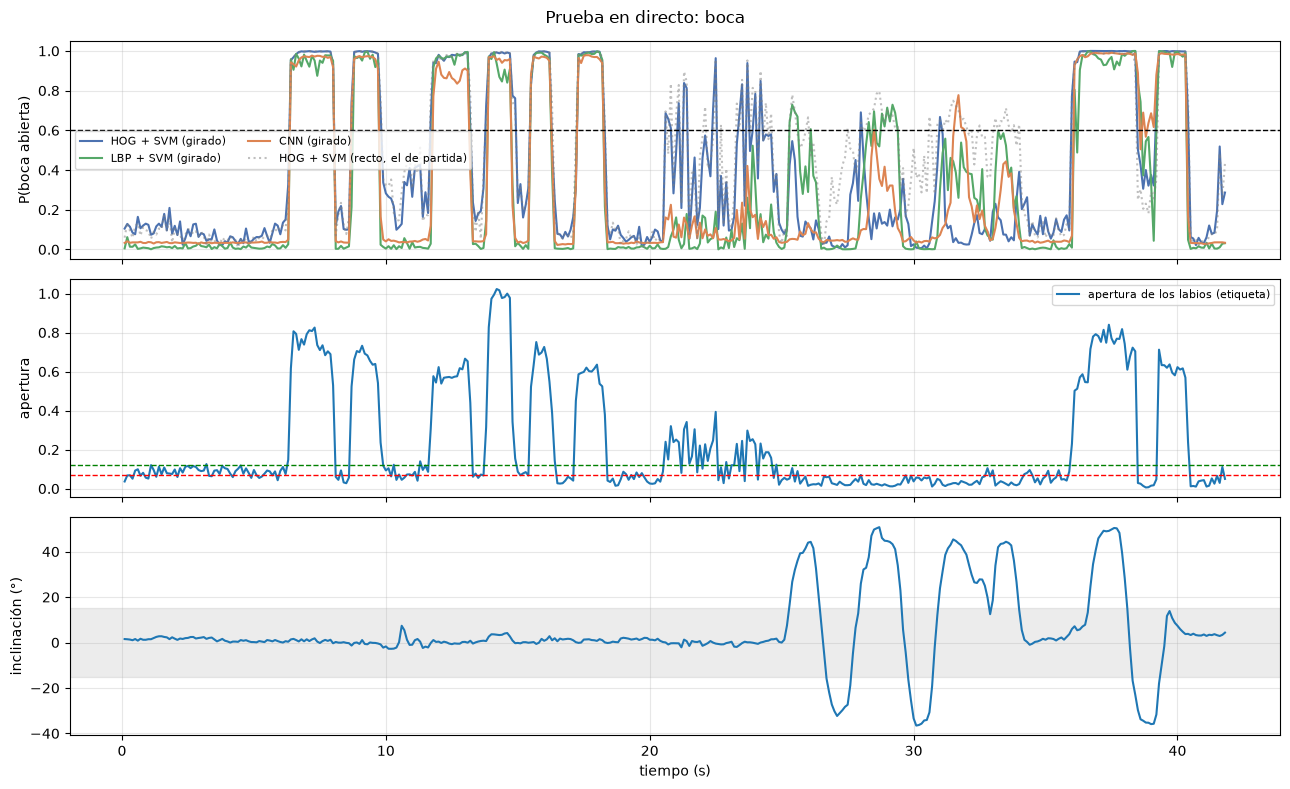

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

# Probabilidad de boca abierta de cada modelo
for nombre, color in zip(modelos, ['#4C72B0', '#55A868', '#DD8452']):
    axs[0].plot(t, tabla[(nombre, 'girado')]['p'], label=f'{nombre} (girado)', color=color)

axs[0].plot(t, tabla[('HOG + SVM', 'recto')]['p'], label='HOG + SVM (recto, el de partida)', color='gray', alpha=0.5, ls=':')
axs[0].axhline(U, color='k', ls='--', lw=1)
axs[0].set_ylabel('P(boca abierta)'); axs[0].legend(fontsize=8, ncol=2)

# Apertura de los labios
axs[1].plot(t, apertura, label='apertura de los labios (etiqueta)')
axs[1].axhline(ABIERTA, color='g', ls='--', lw=1); axs[1].axhline(CERRADA, color='r', ls='--', lw=1)
axs[1].set_ylabel('apertura'); axs[1].legend(fontsize=8)

# Inclinación de la cabeza
axs[2].plot(t, inclinacion); axs[2].axhspan(-15, 15, color='gray', alpha=0.15)
axs[2].set_ylabel('inclinación (°)'); axs[2].set_xlabel('tiempo (s)')

for ax in axs:
    ax.grid(alpha=0.3)

plt.suptitle('Prueba en directo: boca')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/boca_prueba_directo_serie.png', dpi=110)
plt.show()

---

## 3. Modelo de boca para el juego

**Criterio de elección**: entre las variantes que detectan al menos el 90 % de las aperturas grandes, la que **menos falsos disparos** da con la boca cerrada.

- `figuras/boca_directo_resumen.png`: comparación de variantes con la elegida resaltada con una estrella.
- `resultados/boca_directo_resumen.md` y `.json`: tabla, variante elegida y motivo.

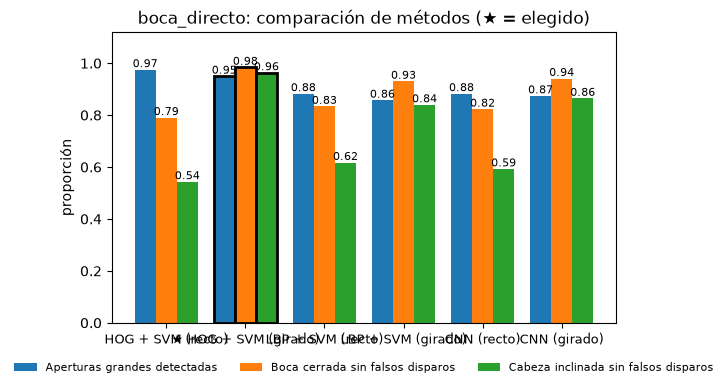

## Modelo de boca: prueba en directo (modelo usado en el juego)

| Método | Aperturas grandes detectadas | Boca cerrada sin falsos disparos | Cabeza inclinada sin falsos disparos |
|---|---|---|---|
| HOG + SVM (recto) | 0.975 | 0.790 | 0.543 |
| **HOG + SVM (girado)** ★ | 0.950 | 0.984 | 0.963 |
| LBP + SVM (recto) | 0.882 | 0.833 | 0.617 |
| LBP + SVM (girado) | 0.857 | 0.930 | 0.840 |
| CNN (recto) | 0.882 | 0.823 | 0.593 |
| CNN (girado) | 0.874 | 0.941 | 0.864 |

**Modelo elegido:** HOG + SVM (girado)

**Motivo:** En la grabación de prueba, HOG + SVM (girado) solo dispara en el 1.6 % de los fotogramas con la boca cerrada (3.7 % con la cabeza inclinada) y detecta el 95 % de las aperturas grandes. El modelo elegido por k-fold (HOG + SVM con el recorte sin girar) daba un 21.0 % de falsos disparos (45.7 % con la cabeza inclinada).

Guardado: figuras\boca_directo_resumen.png, resultados/boca_directo_resumen.md y .json


In [ ]:
# Variantes que detectan al menos el 90 % de las aperturas grandes
validas = []
for k, v in tabla.items():
    if v['grandes'] >= 0.9:
        validas.append(k)

# La que menos falsos disparos da
elegida, falsos_elegida = None, float('inf')

for k in validas:
    if tabla[k]['falsos'] < falsos_elegida:
        elegida, falsos_elegida = k, tabla[k]['falsos']

nombre_elegida = f'{elegida[0]} ({elegida[1]})'
partida = tabla[('HOG + SVM', 'recto')]

filas_resumen = []

for (nombre, recorte), v in tabla.items():
    filas_resumen.append({'Método': f'{nombre} ({recorte})',
                          'Aperturas grandes detectadas': v['grandes'],
                          'Boca cerrada sin falsos disparos': 1 - v['falsos'],
                          'Cabeza inclinada sin falsos disparos': 1 - v['falsos_inclinada'], 'ms': None})

motivo = (f"En la grabación de prueba, {nombre_elegida} solo dispara en el {100 * tabla[elegida]['falsos']:.1f} % de los "
          f"fotogramas con la boca cerrada ({100 * tabla[elegida]['falsos_inclinada']:.1f} % con la cabeza inclinada) y "
          f"detecta el {100 * tabla[elegida]['grandes']:.0f} % de las aperturas grandes. El modelo elegido por k-fold "
          f"(HOG + SVM con el recorte sin girar) daba un {100 * partida['falsos']:.1f} % de falsos disparos "
          f"({100 * partida['falsos_inclinada']:.1f} % con la cabeza inclinada).")

guarda_resumen('boca_directo', filas_resumen, nombre_elegida, motivo,
               ['Aperturas grandes detectadas', 'Boca cerrada sin falsos disparos', 'Cabeza inclinada sin falsos disparos'],
               titulo='## Modelo de boca: prueba en directo (modelo usado en el juego)')

---

## 4. Conclusiones

| Variante | Falsos disparos | … con cabeza inclinada | Aperturas grandes | Aperturas leves (hablar) |
|---|---|---|---|---|
| HOG + SVM, recto (elegido por k-fold) | 21,0 % | 45,7 % | 97,5 % | 39,4 % |
| **HOG + SVM, girado** ★ | **1,6 %** | **3,7 %** | 95,0 % | 33,3 % |
| LBP + SVM, recto | 16,7 % | 38,3 % | 88,2 % | 0,0 % |
| LBP + SVM, girado | 7,0 % | 16,0 % | 85,7 % | 0,0 % |
| CNN, recto | 17,7 % | 40,7 % | 88,2 % | 0,0 % |
| CNN, girado | 5,9 % | 13,6 % | 87,4 % | 0,0 % |

La comparación y la variante elegida quedan guardadas en `figuras/boca_directo_resumen.png` y `resultados/boca_directo_resumen.md`.

1. **El problema en directo no era el modelo, sino el recorte.** Con el recorte sin girar (como en el entrenamiento), todos los modelos disparan con la boca cerrada en el 17–21 % de los fotogramas, y en el 38–46 % con la cabeza inclinada.
    * **Girar el recorte para alinear la boca** los reduce en todos: HOG + SVM pasa del 21 % al 1,6 % de falsos disparos (del 46 % al 3,7 % con la cabeza inclinada).
    * Los datos de entrenamiento eran casi siempre caras rectas, así que alinear la boca acerca la imagen de la webcam a lo que el modelo conoce.
2. **Con el recorte girado, HOG + SVM es la mejor variante**: es la que menos dispara con la boca cerrada y la que más aperturas grandes detecta (95 %), así que **coincide con el modelo elegido por k-fold** (F1 0,983). La CNN girada queda cerca (5,9 % de falsos disparos y 87 % de aperturas detectadas).
3. **Al hablar**, HOG + SVM detecta un 33 % de las aperturas leves, mientras que LBP y la CNN, entrenados con bostezos, no detectan ninguna.
    * En el juego no se habla mientras se juega, así que se prioriza tener pocos falsos disparos con la boca cerrada.
4. **Lección sobre la forma de probar**: en la primera prueba (grabación de pantalla) la CNN parecía muy superior a HOG (1,7 % frente a 17,4 % de falsos disparos con el recorte girado).
    * Esa grabación incluía los recuadros que dibuja `gestos.py`, que caen justo en el borde del recorte de la boca; como HOG describe bordes, esas líneas lo perjudicaban mucho más que a la CNN.
    * Con la grabación limpia la diferencia desaparece. Por eso se añadió la tecla **R**, que graba la imagen de la cámara antes de dibujar nada.
5. **Limitaciones**: una sola persona, una sola cámara y etiquetas obtenidas de una medida geométrica (no etiquetado manual); los fotogramas con apertura dudosa (entre 0,07 y 0,12) se descartan.

> El modelo de boca usado en el juego es **HOG + SVM con el recorte girado** (`modelos/boca_hog`, función `recorta_boca` de `gestos.py`).

---